# Solving Inverse Problem using Connectome Spectrum Electromagnetic Tomography (CSET)

In this section we will solve the inverse problem using our new method CSET. This requires the eeg measurements, the forward solution and the connectome spectrum transform (prior). <br>
The method solves the following problem: $$\vec{x}^* = \text{argmin}_{\vec{x}} \lVert A\vec{x}-b \rVert_2^2 + \lambda \lVert F\vec{x}\rVert_1$$
where
- $\vec{x}^* \in \mathbb{R}^n$ is the reconstructed brain activity.
- $\vec{x} \in \mathbb{R}^n$ is the brain activity.
- $\vec{b} \in \mathbb{R}^m$ are the eeg measurements.
- $A \in \mathbb{R}^{m\times n}$ is the forward matrix.
- $F \in \mathbb{R}^{n \times n}$ is the connectome spectrum transform.
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert F\vec{x} \rVert_1$ imposes the connectome spectrum of $\vec{x}$ to be sparse and $\lambda$ 

## Imports

In [34]:
#%matplotlib qt

import mindmap as mm
import mne
import numpy as np
from pathlib import Path

import pyxu.abc as pxa
import pyxu.operator as pxo 
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

config = mm.io.read_config("../configurations/spike.yml")
mm_dir = Path(config["MM_DIR"])
fs_dir = Path(config["FS_DIR"])

## Data

In [109]:
sub     = "sub-pat27"

# files
forward = mm_dir/sub/"fwd"/f"{sub}_surf-fwd.fif"
cst     = mm_dir/sub/"cst"/f"{sub}_cst-template.npy"
eeg     = mm_dir/sub/"eeg"/f"{sub}_ave.fif"

# parameters
lam           = 0.01
initial_guess = "adjoint"

pyxu_kwargs = dict(
    folder = "solverOutput/",
    exist_ok = True,
    writeback_rate = 1000,
    verbosity = 1,
    show_progress = False,
    log_var = "x",
)

# plotting parameters
plot_kwargs = dict(
    subject = sub, 
    hemi = "both", 
    surface = "white",
    smoothing_steps = 10,
    subjects_dir = fs_dir,
)

# load
eeg       = mne.read_evokeds(eeg)[0]
forward   = mne.read_forward_solution(forward)
cst       = np.load(cst, allow_pickle=True)

Reading /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/mindmap/sub-pat27/eeg/sub-pat27_ave.fif ...
    Found the data of interest:
        t =       0.00 ...     996.00 ms (No comment)
        0 CTF compensation matrices available
        nave = 1 - aspect type = 100
No projector specified for this dataset. Please consider the method self.add_proj.
No baseline correction applied
Reading forward solution from /home/admin/work/data/eeg_epi_spikeerp_data_1.0.0/derivatives/mindmap/sub-pat27/fwd/sub-pat27_surf-fwd.fif...
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    2 source spaces read
    Desired named matrix (kind = 3523) not available
    Read EEG forward solution (6924 sources, 204 channels, free orientations)
    Source spaces transform

## Fix orientations in forward matrix
The forward solution predicts the sensor measurements given the activity at the sources which are dipoles. Dipoles are 3D models of synaptic currents and are thus represented by a value and an orientation. The connectome in CSET does not take into account any direction so to run CSET we fix the orientation according to the normal of the cortical surfaces. This limits CSET to cortical sources since we can't predict the orientation of dipoles in sub-cortical part.

In [110]:
fwd = forward.copy()
fwd = mne.convert_forward_solution(
    fwd,
    surf_ori=True,
    force_fixed=True,
    use_cps=True,
    verbose="warning",
)

fwd  = fwd["sol"]["data"].astype("float64")

## Select time points to reconstruct

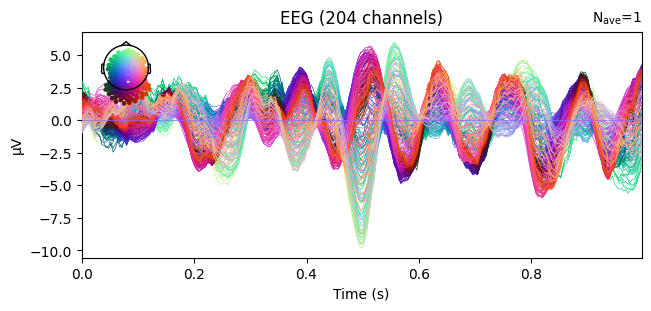

In [111]:
_ = eeg.plot()

Number of time points: (204, 25)


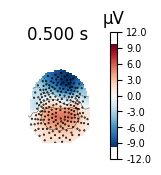

In [112]:
tmin  = 0.45
tmax  = 0.55
tviz  = 0.5
sfreq = eeg.info["sfreq"]

b = eeg.get_data("eeg", tmin=tmin, tmax=tmax)

print(f"Number of time points: {b.shape}")
_ = eeg.plot_topomap([tviz], outlines=None, extrapolate="local")

Write optimization problem

In [6]:
# Depth weighting
A_norms = np.linalg.norm(fwd, ord=2, axis=0)
A       = fwd/A_norms[None,:]

# data normalization
y_norms = np.linalg.norm(b, ord=2, axis=0)
y       = b/y_norms[None,:]

# initial guess
alpha0 = np.zeros(fwd.shape[1])

# operators
A       = pxa.LinOp.from_array(A@cst.T)             
l1_norm = lam*pxo.L1Norm(dim_shape=alpha0.shape[0])

solution = np.zeros((fwd.shape[1], b.shape[1]))
for i in range(b.shape[1]):
    l22_loss = pxo.SquaredL2Norm(dim_shape=A.codim_shape[0]).argshift(-y[:,i]) * A
    l22_loss.diff_lipschitz = l22_loss.estimate_diff_lipschitz()

    solver = PGD(f=l22_loss, g=l1_norm, show_progress=False)

    solver.fit(x0=np.zeros(l22_loss.dim_shape), acceleration=True)
    
    alpha    = solver.solution().squeeze()
    solution[:,i] = cst.T@alpha*y_norms[i]*A_norms

## Visualize

In [7]:
mm.viz.plot_brain_time_series(forward["src"], np.abs(solution), sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:44795/index.html?ui=P_0x7f8292d6ab40_0&reconnect=auto" class="pyvi…

## Other visualization (with time series info)

In [8]:
vertices = [forward["src"][0]["vertno"], forward["src"][1]["vertno"]]
stc = mne.SourceEstimate(np.abs(solution), vertices, tmin=0, tstep=1/sfreq, subject=sub)
stc.data = np.abs(stc.data) + 1e-13     # avoid log10(0) in plot when no brain acitivity
stc.plot(**plot_kwargs)

Using pyvistaqt 3d backend.

Using control points [0.00122736 0.00145827 0.00423704]
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


## Save result

In [9]:
save = "mne"
#save = "bv"

fname  = f"{sub}_cset-{lam}"
folder = mm_dir/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving estimation of subject: {sub}")
if save == "mne":
    stc.save(folder/fname, overwrite=True)
if save == "bv":
    trans = mm.utils.compute_transformation(sub, fs_dir, "mri", "head", "m")
    mm.io.write_stc(
        fname  = fname,
        folder = folder,
        stc    = stc, 
        src    = forward["src"],
        trans  = trans, 
        overwrite = True, 
    )

Writing STC to disk...
[done]


# Test some stuff

In [8]:
from pyxu.opt.solver import PGD

sol = np.zeros_like(alpha0) 

for i in range(b.shape[1]):
    A        = pxa.LinOp.from_array(fwd)
    l22_loss = (1/2)*pxo.SquaredL2Norm(dim_shape=A.codim_shape).argshift(-b[:,i]) * A
    l22_loss.diff_lipschitz = l22_loss.estimate_diff_lipschitz()  
    l22_norm = pxo.SquaredL2Norm(dim_shape=l22_loss.dim_shape)

    solver = PGD(f=l22_loss, g=l22_norm, show_progress=False)

    solver.fit(x0=alpha0[:,i])
    sol[:,i] = solver.solution()

In [ ]:
mm.viz.plot_brain_time_series(forward["src"], np.abs(sol), sfreq, cmap="jet")

Widget(value='<iframe src="http://localhost:36309/index.html?ui=P_0x7f3dc83243b0_0&reconnect=auto" class="pyvi…

Exception raised
ConnectionResetError('Cannot write to closing transport')
Traceback (most recent call last):
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/wslink/protocol.py", line 317, in onCompleteMessage
    await self.sendWrappedMessage(
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/wslink/protocol.py", line 418, in sendWrappedMessage
    await ws.send_bytes(chunk)
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/aiohttp/web_ws.py", line 342, in send_bytes
    await self._writer.send(data, binary=True, compress=compress)
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/aiohttp/http_websocket.py", line 727, in send
    await self._send_frame(message, WSMsgType.BINARY, compress)
  File "/home/admin/miniconda3/envs/mindmap/lib/python3.12/site-packages/aiohttp/http_websocket.py", line 682, in _send_frame
    self._write(header + message)
  File "/home/admin/miniconda3/envs/mindmap/lib

In [13]:
# forward * connectome spectrum
A = fwd@cst.T

# Depth weighting
A_norms = np.linalg.norm(A, ord=2, axis=0)
A       = A/A_norms[None,:]

# data normalization
y_norms = np.linalg.norm(b, ord=2, axis=0)
y       = b/y_norms[None,:]

# initial guess
alpha0 = np.zeros(fwd.shape[1])

# operators
A       = pxa.LinOp.from_array(A)             
l1_norm = lam*pxo.L1Norm(dim_shape=alpha0.shape[0])

solution = np.zeros((fwd.shape[1], b.shape[1]))
for i in range(b.shape[1]):
    l22_loss = pxo.SquaredL2Norm(dim_shape=A.codim_shape[0]).argshift(-y[:,i]) * A
    l22_loss.diff_lipschitz = l22_loss.estimate_diff_lipschitz()

    solver = PGD(f=l22_loss, g=l1_norm, show_progress=False)

    solver.fit(x0=np.zeros(l22_loss.dim_shape), acceleration=True)
    
    alpha    = solver.solution().squeeze()
    solution[:,i] = cst.T@alpha*y_norms[i]*A_norms

In [14]:
mm.viz.plot_brain_time_series(forward["src"], np.abs(solution), sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:44339/index.html?ui=P_0x7fbd8e6c2db0_0&reconnect=auto" class="pyvi…

In [15]:
vertices = [forward["src"][0]["vertno"], forward["src"][1]["vertno"]]
stc = mne.SourceEstimate(np.abs(solution), vertices, tmin=0, tstep=1/sfreq, subject=sub)
stc.data = np.abs(stc.data) + 1e-13     # avoid log10(0) in plot when no brain acitivity
stc.plot(**plot_kwargs)

Using pyvistaqt 3d backend.

Using control points [0.00160106 0.00217956 0.01600302]


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


In [16]:
save = "mne"
#save = "bv"

fname  = f"{sub}_cset2-{lam}"
folder = mm_dir/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving estimation of subject: {sub}")
if save == "mne":
    stc.save(folder/fname, overwrite=True)
if save == "bv":
    trans = mm.utils.compute_transformation(sub, fs_dir, "mri", "head", "m")
    mm.io.write_stc(
        fname  = fname,
        folder = folder,
        stc    = stc, 
        src    = forward["src"],
        trans  = trans, 
        overwrite = True, 
    )

Saving estimation of subject: sub-pat09
Writing STC to disk...
[done]
